# 02 - Feature understanding and reduction
**Author: Ayush Raj(MS23255).**

In [1]:
import sys, warnings
from pathlib import Path
# find the project root (works wherever VS Code starts the notebook)
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(root))
warnings.filterwarnings("ignore")
from IPython.display import Image, display
import pandas as pd
from src import feature_reduction as fr
from src.data_loader import get_xy
X, y, cols = get_xy()
print(X.shape)

(1000, 57)


## 1. Correlated features

In [2]:
kept, dropped = fr.drop_correlated(X, 0.90)
print('kept', len(kept), 'dropped', len(dropped))
dropped

kept 54 dropped 3


['spectral_bandwidth_mean', 'rolloff_mean', 'mfcc2_mean']

## 2. PCA

components for 95% variance: 33


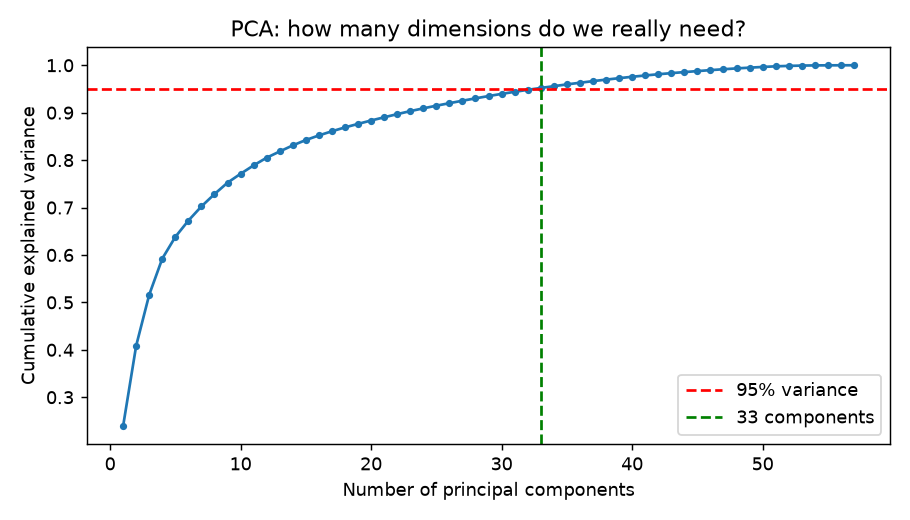

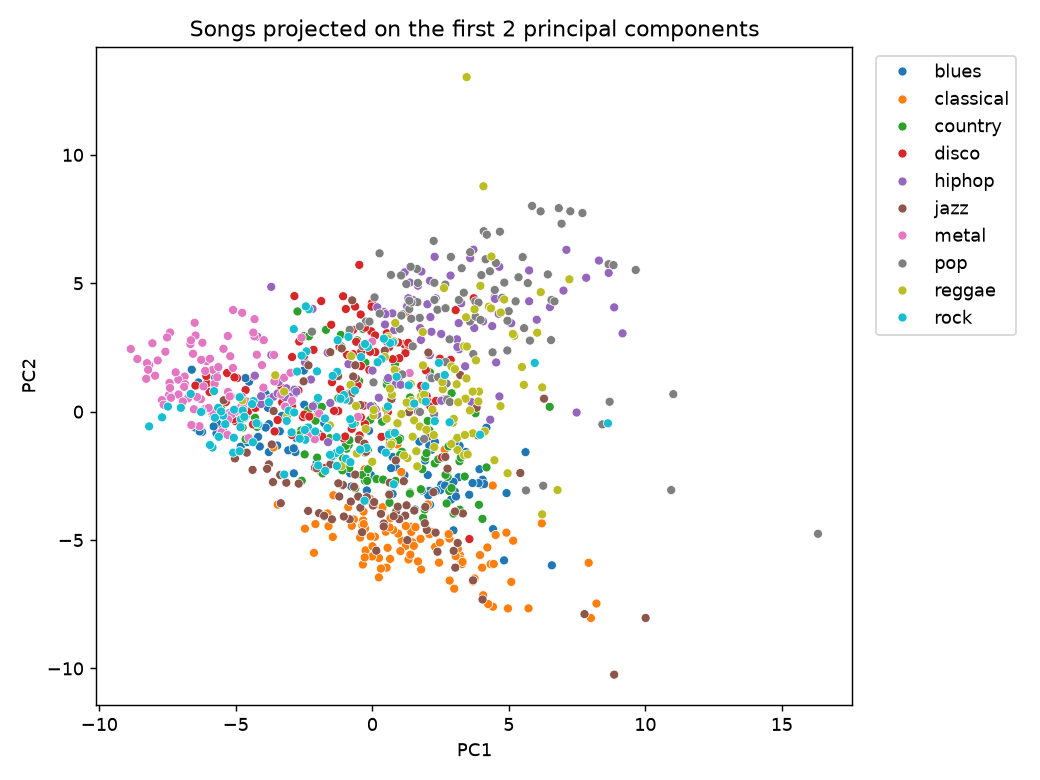

In [3]:
n95 = fr.plot_pca_variance(X)
print('components for 95% variance:', n95)
display(Image(str(root / 'reports/figures/07_pca_variance.png')))
fr.plot_pca_2d(X, y)
display(Image(str(root / 'reports/figures/08_pca_2d.png')))

## 3. Random Forest importance

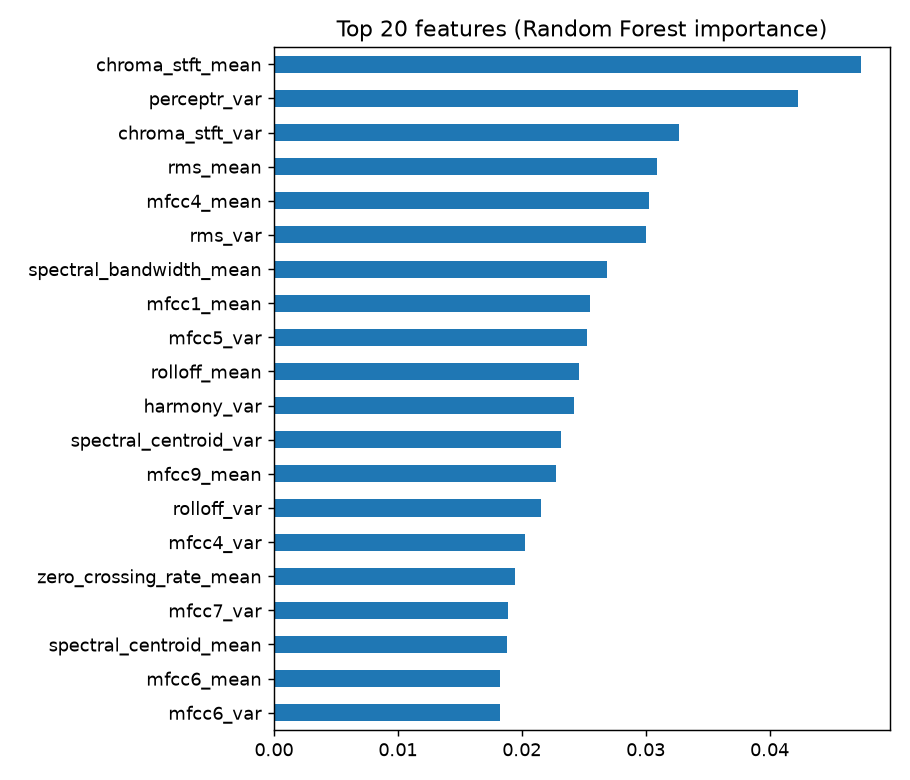

chroma_stft_mean           0.047390
perceptr_var               0.042268
chroma_stft_var            0.032661
rms_mean                   0.030927
mfcc4_mean                 0.030260
rms_var                    0.030046
spectral_bandwidth_mean    0.026904
mfcc1_mean                 0.025534
mfcc5_var                  0.025292
rolloff_mean               0.024634
dtype: float64

In [4]:
imp = fr.plot_importance(X, y)
display(Image(str(root / 'reports/figures/09_feature_importance.png')))
imp.head(10)

## 4. Does reducing features hurt accuracy? (same SVM, 5-fold CV)

In [5]:
result = fr.compare_feature_sets(X, y, kept, n95)
result

{'feature_set': 'All features', 'n_features': 57, 'cv_accuracy_mean': 0.73, 'cv_accuracy_std': 0.029}
{'feature_set': 'Correlation pruning (|r|>0.90)', 'n_features': 54, 'cv_accuracy_mean': 0.737, 'cv_accuracy_std': 0.0256}
{'feature_set': 'PCA (33 comps, 95% var)', 'n_features': 33, 'cv_accuracy_mean': 0.731, 'cv_accuracy_std': 0.0314}
{'feature_set': 'Top-20 by RF importance', 'n_features': 20, 'cv_accuracy_mean': 0.702, 'cv_accuracy_std': 0.0256}


,feature_set,n_features,cv_accuracy_mean,cv_accuracy_std
0,All features,57,0.730,0.0290
1,Correlation pruning (|r|>0.90),54,0.737,0.0256
2,"PCA (33 comps, 95% var)",33,0.731,0.0314
3,Top-20 by RF importance,20,0.702,0.0256


## Conclusion (fill in)
- How many features can we remove with little accuracy loss?
- Which feature groups matter most (MFCC, chroma, tempo...)?